### **0. Environment Setup**

In [1]:
#Import Libs
import sklearn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler

In [2]:
#Define Colors Palette and Standards for Illustrations
RED, DARK, GRAY, LIGHT, SOFT = "#CD2027", "#404040", "#7F7F7F", "#D9D9D9", "#E9A0A3"

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams.update({
    "figure.figsize": (7.5, 4.2),
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.titleweight": "bold",
    "axes.prop_cycle": cycler(color=[RED, DARK, SOFT, GRAY]),
})
pd.set_option("display.precision", 3)
pd.set_option("display.width", 120)

In [3]:
#Helper Functions: Evaluation Reports ( Confusion Matrix, Metrics, ROC and Precision-Recall )
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, average_precision_score, log_loss, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve)

def plot_confusion(cm, labels, ax, title="Confusion matrix"):
    ax.imshow(cm, cmap="Reds"); ax.grid(False)
    ax.set_xticks(range(len(labels))); ax.set_xticklabels(labels, rotation=45 if len(labels) > 4 else 0, ha="right" if len(labels) > 4 else "center")
    ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels)
    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=10 if len(labels) > 4 else 13,
                    color="white" if cm[i, j] > cm.max() / 2 else DARK)
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)

def report_binary(y_true, y_pred, y_score, name="model", labels=("negative", "positive"), plot=True):
    """Confusion matrix, ROC and Precision-Recall curves + a Series with the main metrics (positive class = 1)."""
    y_true, y_pred, y_score = np.asarray(y_true), np.asarray(y_pred), np.asarray(y_score)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "precision": precision_score(y_true, y_pred, zero_division=0), "recall": recall_score(y_true, y_pred),
               "F1": f1_score(y_true, y_pred), "MCC": matthews_corrcoef(y_true, y_pred),
               "ROC AUC": roc_auc_score(y_true, y_score), "PR AUC": average_precision_score(y_true, y_score)}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
        plot_confusion(confusion_matrix(y_true, y_pred), list(labels), axes[0], f"Confusion matrix – {name}")
        fpr, tpr, _ = roc_curve(y_true, y_score)
        axes[1].plot(fpr, tpr, color=RED, lw=2.4, label=f"AUC = {metrics['ROC AUC']:.3f}"); axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--")
        axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate"); axes[1].set_title("ROC curve"); axes[1].legend(loc="lower right")
        p, r, _ = precision_recall_curve(y_true, y_score)
        axes[2].plot(r, p, color=DARK, lw=2.4, label=f"AP = {metrics['PR AUC']:.3f}"); axes[2].axhline(y_true.mean(), color=GRAY, ls="--")
        axes[2].set_xlabel("recall"); axes[2].set_ylabel("precision"); axes[2].set_title("Precision–Recall curve"); axes[2].legend(loc="lower left")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)

def report_multiclass(y_true, y_pred, y_proba, labels, name="model", plot=True):
    """Confusion matrix, one-vs-rest ROC curves and per-class F1 + a Series with the main metrics."""
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    k = len(labels)
    metrics = {"accuracy": accuracy_score(y_true, y_pred), "balanced acc.": balanced_accuracy_score(y_true, y_pred),
               "macro precision": precision_score(y_true, y_pred, average="macro", zero_division=0),
               "macro recall": recall_score(y_true, y_pred, average="macro"), "macro F1": f1_score(y_true, y_pred, average="macro"),
               "MCC": matthews_corrcoef(y_true, y_pred), "ROC AUC (ovr)": roc_auc_score(y_true, y_proba, multi_class="ovr"),
               "log loss": log_loss(y_true, y_proba, labels=list(range(k)))}
    if plot:
        fig, axes = plt.subplots(1, 3, figsize=(15, 4.4), gridspec_kw={"width_ratios": [1.1, 1, 1]})
        plot_confusion(confusion_matrix(y_true, y_pred, labels=list(range(k))), list(labels), axes[0], f"Confusion matrix – {name}")
        cmap = plt.get_cmap("tab10")
        for c in range(k):
            fpr, tpr, _ = roc_curve((y_true == c).astype(int), y_proba[:, c])
            axes[1].plot(fpr, tpr, color=cmap(c), lw=1.6, label=f"{labels[c]}")
        axes[1].plot([0, 1], [0, 1], color=GRAY, ls="--"); axes[1].set_xlabel("false positive rate"); axes[1].set_ylabel("true positive rate")
        axes[1].set_title(f"ROC one-vs-rest (macro AUC = {metrics['ROC AUC (ovr)']:.3f})"); axes[1].legend(fontsize=7, ncol=2 if k > 5 else 1, loc="lower right")
        f1s = f1_score(y_true, y_pred, average=None)
        axes[2].bar(range(k), f1s, color=RED, width=0.65); axes[2].set_xticks(range(k)); axes[2].set_xticklabels(labels, rotation=45 if k > 4 else 0, ha="right" if k > 4 else "center")
        axes[2].set_ylim(0, 1.05); axes[2].set_ylabel("F1"); axes[2].set_title("F1 per class")
        plt.tight_layout(); plt.show()
    return pd.Series(metrics, name=name)
def annotate_heatmap(ax, mat, fmt="{:.2f}"):
    """Write the values on an imshow heat map with a readable text color."""
    mat = np.asarray(mat, dtype=float)
    lo, hi = np.nanmin(mat), np.nanmax(mat)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            v = mat[i, j]
            ax.text(j, i, "–" if np.isnan(v) else fmt.format(v), ha="center", va="center", color="white" if (not np.isnan(v) and v > (lo + hi) / 2) else DARK)

### **1. Association Rule Mining**

Finds **items that occur together** (market-basket analysis) in two steps:

1. **Frequent itemsets:** all sets of items with support ≥ *min_support*
2. **Rules** $A \Rightarrow B$ from those itemsets, filtered by confidence, lift…

| Algorithm | Strategy | Key idea |
|---|---|---|
| **Apriori** | breadth-first, level by level | *a superset of an infrequent set is infrequent* (pruning) |
| **FP-Growth** | divide and conquer | compress the data in an **FP-tree**; no candidate generation |
| **Eclat** | depth-first on **tid-lists** | support = size of the **intersection** of transaction lists |

All three return **exactly the same itemsets** (we will check it).

### **2. Dataset: Simulated Retail Baskets**

6 000 baskets generated from **shopper profiles** (breakfast, party, family dinner, baby, healthy), so that natural associations appear, a mild unexpected one (*diapers ⟶ beer*) and a **loyalty-card bundle** (diapers always come with the baby club card).

In [4]:
#Generate the Transactions ( Shopper Profiles + Random Background Items )
rng = np.random.default_rng(RANDOM_STATE)
profiles = {
    "breakfast":     {"bread": .70, "butter": .50, "jam": .35, "milk": .60, "coffee": .50, "sugar": .30, "eggs": .40, "cereal": .30},
    "party":         {"beer": .60, "chips": .60, "soda": .50, "pizza": .35, "ice": .30, "peanuts": .30},
    "family dinner": {"pasta": .60, "tomato_sauce": .50, "cheese": .40, "chicken": .40, "rice": .40, "beans": .30, "salad": .30, "tomato": .30},
    "baby":          {"diapers": .80, "baby_food": .50, "wipes": .50, "milk": .40, "beer": .25},
    "healthy":       {"salad": .60, "fruit": .70, "yogurt": .50, "fish": .40, "lemon": .30, "water": .60, "tomato": .30},
}
items = sorted({i for p in profiles.values() for i in p} | {"baby_club_card"})

def make_basket():
    chosen = rng.choice(list(profiles), size=1 if rng.random() < 0.75 else 2, replace=False)
    basket = {i for p in chosen for i, prob in profiles[p].items() if rng.random() < prob}
    basket |= {i for i in items if rng.random() < 0.025}                      # random background items
    if "diapers" in basket:
        basket.add("baby_club_card")                                           # loyalty-card bundle (always together)
    return frozenset(basket) if basket else frozenset([str(rng.choice(items))])

transactions = [make_basket() for _ in range(6000)]
print("transactions:", len(transactions), "| distinct items:", len(items), "| mean basket size:", round(np.mean([len(t) for t in transactions]), 2))
for t in transactions[:3]:
    print("  ", sorted(t))

transactions: 6000 | distinct items: 31 | mean basket size: 4.72
   ['beans', 'fruit', 'pasta', 'tomato', 'water']
   ['fruit', 'salad', 'tomato_sauce']
   ['fish', 'fruit', 'salad', 'yogurt']


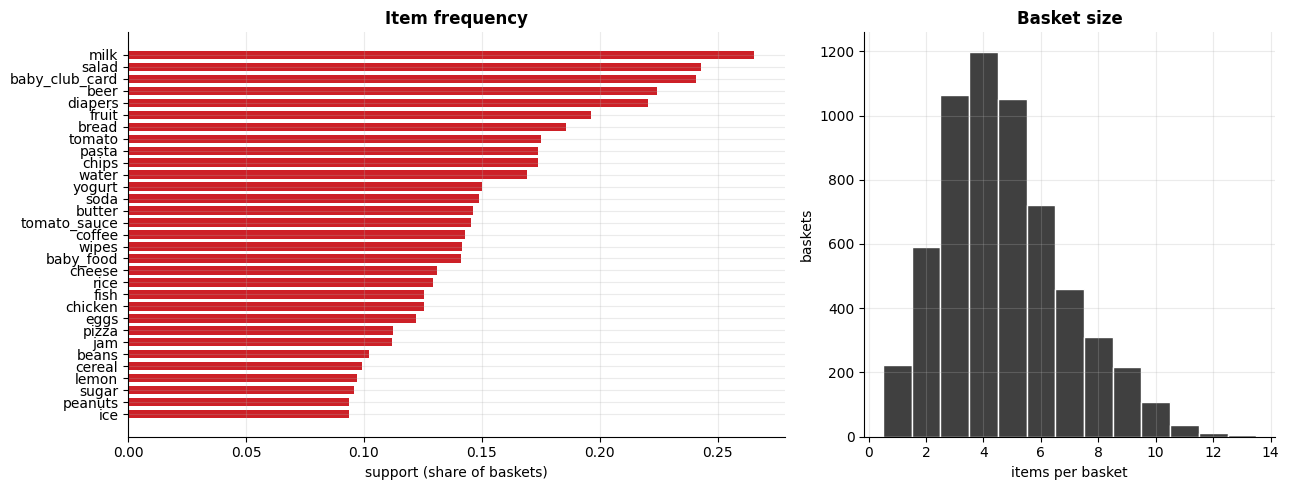

In [5]:
#Explore the Data ( Item Frequency and Basket Size )
freq_items = pd.Series({i: sum(i in t for t in transactions) / len(transactions) for i in items}).sort_values()
sizes = pd.Series([len(t) for t in transactions])

fig, axes = plt.subplots(1, 2, figsize=(13, 5), gridspec_kw={"width_ratios": [1.6, 1]})
axes[0].barh(freq_items.index, freq_items.values, color=RED, height=0.7); axes[0].set_xlabel("support (share of baskets)"); axes[0].set_title("Item frequency")
axes[1].hist(sizes, bins=range(1, sizes.max() + 2), color=DARK, edgecolor="white", align="left"); axes[1].set_xlabel("items per basket"); axes[1].set_ylabel("baskets"); axes[1].set_title("Basket size")
plt.tight_layout(); plt.show()

### **3. Rule Metrics**

For a rule $A \Rightarrow B$ (all supports are shares of the baskets):

| Metric | Formula | Reading |
|---|---|---|
| **Support** | $P(A \cap B)$ | how frequent |
| **Confidence** | $P(B \mid A)$ | how reliable |
| **Lift** | $\dfrac{P(B \mid A)}{P(B)}$ | $>1$ positive · $=1$ independent · $<1$ negative |
| **Leverage** | $P(A \cap B) - P(A)P(B)$ | excess co-occurrence over independence |
| **Conviction** | $\dfrac{1 - P(B)}{1 - \text{conf}}$ | how much $A$ without $B$ is *unexpected* ($\infty$ if conf = 1) |
| **Zhang's** | $\dfrac{\text{leverage}}{\max\{P(AB)(1-P(A)),\ P(A)(P(B)-P(AB))\}}$ | association from −1 to +1 |

In [6]:
#Bit-Set Representation ( One Integer per Item = Its Transaction List ) and Rule-Metric Function
from itertools import combinations
from collections import Counter, defaultdict
import time

def build_tidsets(transactions):
    tid = defaultdict(int)
    for t_idx, basket in enumerate(transactions):
        bit = 1 << t_idx
        for item in basket:
            tid[item] |= bit
    return dict(tid)

def rule_metrics(s_a, s_b, s_ab):
    conf = s_ab / s_a
    lev = s_ab - s_a * s_b
    denom = max(s_ab * (1 - s_a), s_a * (s_b - s_ab))
    return {"support": s_ab, "confidence": conf, "lift": conf / s_b, "leverage": lev,
            "conviction": (1 - s_b) / (1 - conf) if conf < 1 else np.inf, "zhangs": lev / denom if denom > 0 else 0.0}

tid_all = build_tidsets(transactions)
N = len(transactions)
print("support(beer) =", tid_all["beer"].bit_count() / N, "| support(diapers) =", tid_all["diapers"].bit_count() / N)
for a, b in [("diapers", "beer"), ("diapers", "baby_club_card")]:
    print(f"rule {a} => {b}:", {k: round(v, 3) for k, v in rule_metrics(tid_all[a].bit_count() / N, tid_all[b].bit_count() / N, (tid_all[a] & tid_all[b]).bit_count() / N).items()})

support(beer) = 0.22433333333333333 | support(diapers) = 0.22033333333333333
rule diapers => beer: {'support': 0.066, 'confidence': 0.301, 'lift': 1.342, 'leverage': 0.017, 'conviction': 1.11, 'zhangs': 0.327}
rule diapers => baby_club_card: {'support': 0.22, 'confidence': 1.0, 'lift': 4.152, 'leverage': 0.167, 'conviction': inf, 'zhangs': 0.974}


### **4. Apriori**

Level by level: **join** frequent $(k{-}1)$-itemsets into $k$-candidates, **prune** candidates that have an infrequent subset and **count** the support of the rest.
Counting uses the **bit-set** of each item (support = number of 1-bits of the AND).

In [7]:
#Apriori Implementation ( Join, Prune and Count ) with Statistics per Level
def apriori(tid, n, min_support):
    min_count = int(np.ceil(min_support * n))
    level = {(i,): m for i, m in sorted(tid.items()) if m.bit_count() >= min_count}
    freq = {k: m.bit_count() for k, m in level.items()}
    stats = [{"k": 1, "joined": len(tid), "after pruning": len(tid), "frequent": len(level)}]
    k = 1
    while level:
        keys = sorted(level)
        prev, cands, joined = set(keys), {}, 0
        for a in range(len(keys)):
            for b in range(a + 1, len(keys)):
                if keys[a][:-1] != keys[b][:-1]:
                    break
                joined += 1
                new = keys[a] + (keys[b][-1],)
                if all(sub in prev for sub in combinations(new, k)):                          # prune: every k-subset must be frequent
                    cands[new] = level[keys[a]] & level[keys[b]]
        level = {c: m for c, m in cands.items() if m.bit_count() >= min_count}
        k += 1
        if joined:
            stats.append({"k": k, "joined": joined, "after pruning": len(cands), "frequent": len(level)})
        freq.update({c: m.bit_count() for c, m in level.items()})
    return {frozenset(c): v / n for c, v in freq.items()}, pd.DataFrame(stats)

t0 = time.perf_counter()
freq_apriori, apriori_stats = apriori(tid_all, N, min_support=0.02)
t_apriori = time.perf_counter() - t0
print(f"frequent itemsets (support ≥ 2%): {len(freq_apriori)} | time: {t_apriori:.2f}s")
apriori_stats

frequent itemsets (support ≥ 2%): 326 | time: 0.00s


,k,joined,after pruning,frequent
0,1,31,31,31
1,2,465,465,150
2,3,548,331,124
3,4,129,67,20
4,5,3,2,1


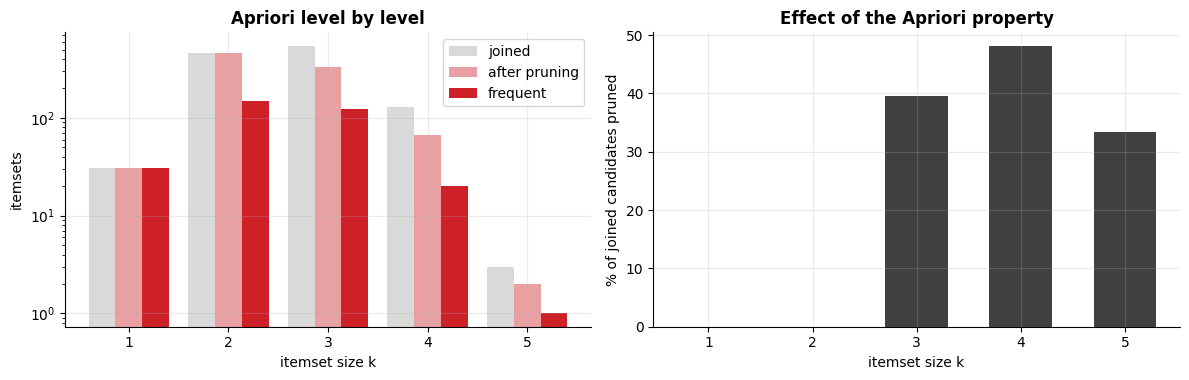

database passes (support counting) = 5 | candidates counted: 896


In [8]:
#Apriori-Specific Metrics: Candidates Generated, Pruned and Frequent per Level
st = apriori_stats
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
x = np.arange(len(st))
axes[0].bar(x - 0.27, st["joined"], 0.27, color=LIGHT, label="joined"); axes[0].bar(x, st["after pruning"], 0.27, color=SOFT, label="after pruning"); axes[0].bar(x + 0.27, st["frequent"], 0.27, color=RED, label="frequent")
axes[0].set_xticks(x); axes[0].set_xticklabels(st["k"]); axes[0].set_xlabel("itemset size k"); axes[0].set_ylabel("itemsets"); axes[0].set_yscale("log"); axes[0].set_title("Apriori level by level"); axes[0].legend()
pruned = (st["joined"] - st["after pruning"]).clip(lower=0)
axes[1].bar(x, pruned / st["joined"].replace(0, 1) * 100, color=DARK, width=0.6); axes[1].set_xticks(x); axes[1].set_xticklabels(st["k"]); axes[1].set_xlabel("itemset size k"); axes[1].set_ylabel("% of joined candidates pruned"); axes[1].set_title("Effect of the Apriori property")
plt.tight_layout(); plt.show()
print("database passes (support counting) =", len(st), "| candidates counted:", int(st["after pruning"].sum()))

### **5. FP-Growth**

1. Count the items and keep the **frequent** ones, ordered by frequency
2. Insert each basket in an **FP-tree** (shared prefixes share nodes → **compression**)
3. For each item (least frequent first) take its **conditional pattern base**, build a conditional FP-tree and **recurse**

In [9]:
#FP-Growth Implementation ( FP-Tree and Conditional Pattern Bases )
class FPNode:
    __slots__ = ("item", "count", "parent", "children")
    def __init__(self, item, parent):
        self.item, self.count, self.parent, self.children = item, 0, parent, {}

def build_fptree(weighted_paths, min_count):
    counts = defaultdict(int)
    for path, c in weighted_paths:
        for i in path:
            counts[i] += c
    order = {i: r for r, (i, _) in enumerate(sorted(((i, c) for i, c in counts.items() if c >= min_count), key=lambda kv: (-kv[1], kv[0])))}
    root, header, n_nodes = FPNode(None, None), defaultdict(list), 0
    for path, c in weighted_paths:
        node = root
        for i in sorted((i for i in path if i in order), key=order.get):
            child = node.children.get(i)
            if child is None:
                child = FPNode(i, node); node.children[i] = child; header[i].append(child); n_nodes += 1
            child.count += c
            node = child
    return root, header, {i: counts[i] for i in order}, n_nodes

def fp_growth(transactions, min_support):
    n, min_count = len(transactions), int(np.ceil(min_support * len(transactions)))
    root, header, item_counts, n_nodes = build_fptree([(list(t), 1) for t in transactions], min_count)
    result = {}

    def mine(header, item_counts, suffix):
        for item in sorted(item_counts, key=lambda i: (item_counts[i], i)):                  # least frequent first
            new_suffix = suffix | {item}
            result[frozenset(new_suffix)] = sum(nd.count for nd in header[item])
            base = []
            for nd in header[item]:                                                        # conditional pattern base
                path, p = [], nd.parent
                while p.item is not None:
                    path.append(p.item); p = p.parent
                if path:
                    base.append((path, nd.count))
            if base:
                _, h2, counts2, _ = build_fptree(base, min_count)
                if counts2:
                    mine(h2, counts2, new_suffix)

    mine(header, item_counts, frozenset())
    return {k: v / n for k, v in result.items()}, {"tree nodes": n_nodes, "items in baskets": sum(len(t) for t in transactions), "depth": max_depth(root)}

def max_depth(node):
    return 0 if not node.children else 1 + max(max_depth(c) for c in node.children.values())

t0 = time.perf_counter()
freq_fp, fp_info = fp_growth(transactions, min_support=0.02)
t_fp = time.perf_counter() - t0
print(f"frequent itemsets: {len(freq_fp)} | time: {t_fp:.2f}s | FP-tree: {fp_info['tree nodes']} nodes for {fp_info['items in baskets']} item occurrences "
      f"(compression {fp_info['items in baskets'] / fp_info['tree nodes']:.1f}×), depth {fp_info['depth']}")

frequent itemsets: 326 | time: 0.04s | FP-tree: 8081 nodes for 28346 item occurrences (compression 3.5×), depth 13


### **6. Eclat**

Works **vertically**: each item keeps its **tid-list** (here, a bit-set). The support of an extension is the **intersection** of two tid-lists, explored **depth-first** inside *equivalence classes* (itemsets with the same prefix).

In [10]:
#Eclat Implementation ( Depth-First Search on Tid-Lists )
def eclat(tid, n, min_support):
    min_count = int(np.ceil(min_support * n))
    base = sorted(((i, m) for i, m in tid.items() if m.bit_count() >= min_count), key=lambda kv: (kv[1].bit_count(), kv[0]))
    result, counter = {}, {"intersections": 0}

    def recurse(prefix, candidates):
        for idx, (item, m) in enumerate(candidates):
            new_prefix = prefix | {item}
            result[frozenset(new_prefix)] = m.bit_count()
            ext = []
            for item2, m2 in candidates[idx + 1:]:
                nm = m & m2
                counter["intersections"] += 1
                if nm.bit_count() >= min_count:
                    ext.append((item2, nm))
            if ext:
                recurse(new_prefix, ext)

    recurse(frozenset(), base)
    return {k: v / n for k, v in result.items()}, counter

t0 = time.perf_counter()
freq_eclat, eclat_info = eclat(tid_all, N, min_support=0.02)
t_eclat = time.perf_counter() - t0
print(f"frequent itemsets: {len(freq_eclat)} | time: {t_eclat:.2f}s | tid-list intersections: {eclat_info['intersections']}")

same = (set(freq_apriori) == set(freq_fp) == set(freq_eclat)) and all(abs(freq_apriori[k] - freq_fp[k]) < 1e-12 and abs(freq_apriori[k] - freq_eclat[k]) < 1e-12 for k in freq_apriori)
print("Apriori, FP-Growth and Eclat return exactly the same itemsets and supports:", same)

frequent itemsets: 326 | time: 0.00s | tid-list intersections: 875
Apriori, FP-Growth and Eclat return exactly the same itemsets and supports: True


### **7. Comparing the Algorithms**

Running time and number of itemsets as the **minimum support** decreases (the lower the threshold, the larger the search space).

,min_support,itemsets,Apriori (s),FP-Growth (s),Eclat (s),FP-tree compression,Eclat intersections
0,0.100,36,0.001,0.024,2.516e-04,4.868,326
1,0.050,104,0.001,0.091,4.267e-04,3.508,515
2,0.030,199,0.002,0.031,7.537e-04,3.508,656
3,0.020,326,0.003,0.037,9.248e-04,3.508,875
4,0.010,806,0.009,0.117,3.016e-03,3.508,3377
5,0.005,2048,0.027,0.135,7.398e-03,3.508,6948
6,0.003,5269,0.041,0.176,1.429e-02,3.508,14641


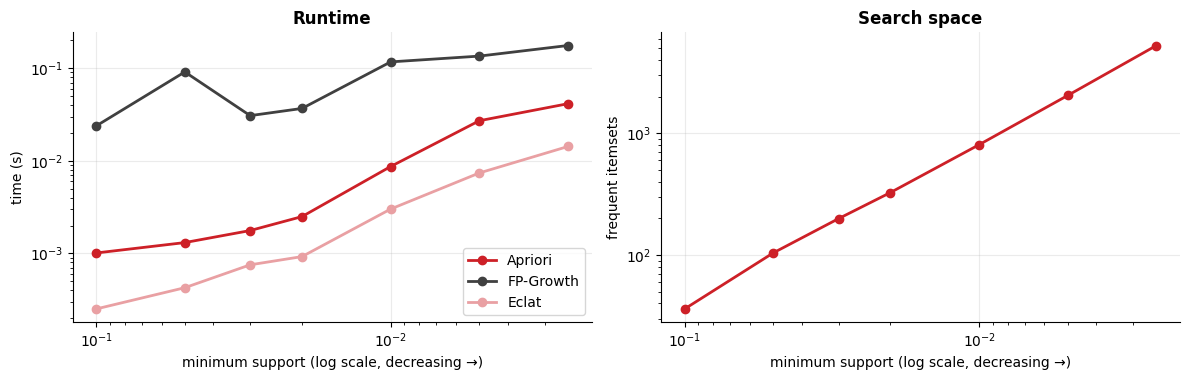

In [11]:
#Runtime and Number of Frequent Itemsets by Minimum Support
rows = []
for ms in [0.10, 0.05, 0.03, 0.02, 0.01, 0.005, 0.0025]:
    t0 = time.perf_counter(); fa, _ = apriori(tid_all, N, ms); ta = time.perf_counter() - t0
    t0 = time.perf_counter(); ff, info = fp_growth(transactions, ms); tf = time.perf_counter() - t0
    t0 = time.perf_counter(); fe, ei = eclat(tid_all, N, ms); te = time.perf_counter() - t0
    assert set(fa) == set(ff) == set(fe)
    rows.append({"min_support": ms, "itemsets": len(fa), "Apriori (s)": ta, "FP-Growth (s)": tf, "Eclat (s)": te,
                 "FP-tree compression": info["items in baskets"] / info["tree nodes"], "Eclat intersections": ei["intersections"]})
bench = pd.DataFrame(rows)
display(bench)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
for col, color in zip(["Apriori (s)", "FP-Growth (s)", "Eclat (s)"], [RED, DARK, SOFT]):
    axes[0].plot(bench["min_support"], bench[col], marker="o", color=color, lw=2, label=col.replace(" (s)", ""))
axes[0].set_xscale("log"); axes[0].set_yscale("log"); axes[0].invert_xaxis(); axes[0].set_xlabel("minimum support (log scale, decreasing →)"); axes[0].set_ylabel("time (s)"); axes[0].set_title("Runtime"); axes[0].legend()
axes[1].plot(bench["min_support"], bench["itemsets"], marker="o", color=RED, lw=2); axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].invert_xaxis()
axes[1].set_xlabel("minimum support (log scale, decreasing →)"); axes[1].set_ylabel("frequent itemsets"); axes[1].set_title("Search space")
plt.tight_layout(); plt.show()

In pure Python with bit-sets, Apriori and Eclat have the lowest constant factors here. The advantage of FP-Growth (no candidate generation) grows with **long patterns** and **dense data**.

### **8. Generating and Ranking the Rules**

From each frequent itemset we try every split `A ⇒ B`; all subsets are frequent, so their supports are already known.

In [12]:
#Generate the Rules with All the Metrics ( min support 2%, min confidence 30% )
def generate_rules(freq, min_confidence=0.3):
    rows = []
    for itemset, s_ab in freq.items():
        if len(itemset) < 2:
            continue
        for r in range(1, len(itemset)):
            for A in combinations(sorted(itemset), r):
                A = frozenset(A); B = itemset - A
                m = rule_metrics(freq[A], freq[B], s_ab)
                if m["confidence"] >= min_confidence:
                    rows.append({"antecedent": tuple(sorted(A)), "consequent": tuple(sorted(B)), **m})
    return pd.DataFrame(rows)

rules = generate_rules(freq_apriori, min_confidence=0.3)
fmt = lambda t: " + ".join(t)
print("rules:", len(rules), "| with lift > 1:", int((rules["lift"] > 1).sum()))
top = rules.sort_values("lift", ascending=False).head(8)
top.assign(antecedent=top["antecedent"].map(fmt), consequent=top["consequent"].map(fmt))[["antecedent", "consequent", "support", "confidence", "lift", "leverage", "conviction", "zhangs"]]

rules: 731 | with lift > 1: 731


,antecedent,consequent,support,confidence,lift,leverage,conviction,zhangs
719,baby_club_card + baby_food + milk,diapers + wipes,0.025,0.517,5.181,0.020,1.865,0.848
720,baby_club_card + baby_food + wipes,diapers + milk,0.025,0.495,5.148,0.020,1.790,0.849
722,baby_food + diapers + milk,baby_club_card + wipes,0.025,0.521,5.131,0.020,1.875,0.846
721,baby_club_card + milk + wipes,baby_food + diapers,0.025,0.523,5.124,0.020,1.881,0.845
725,diapers + milk + wipes,baby_club_card + baby_food,0.025,0.528,5.095,0.020,1.900,0.844
723,baby_food + diapers + wipes,baby_club_card + milk,0.025,0.498,4.934,0.020,1.792,0.839
603,beer + diapers,baby_club_card + wipes,0.033,0.492,4.852,0.026,1.770,0.850
602,baby_club_card + wipes,beer + diapers,0.033,0.322,4.852,0.026,1.377,0.884


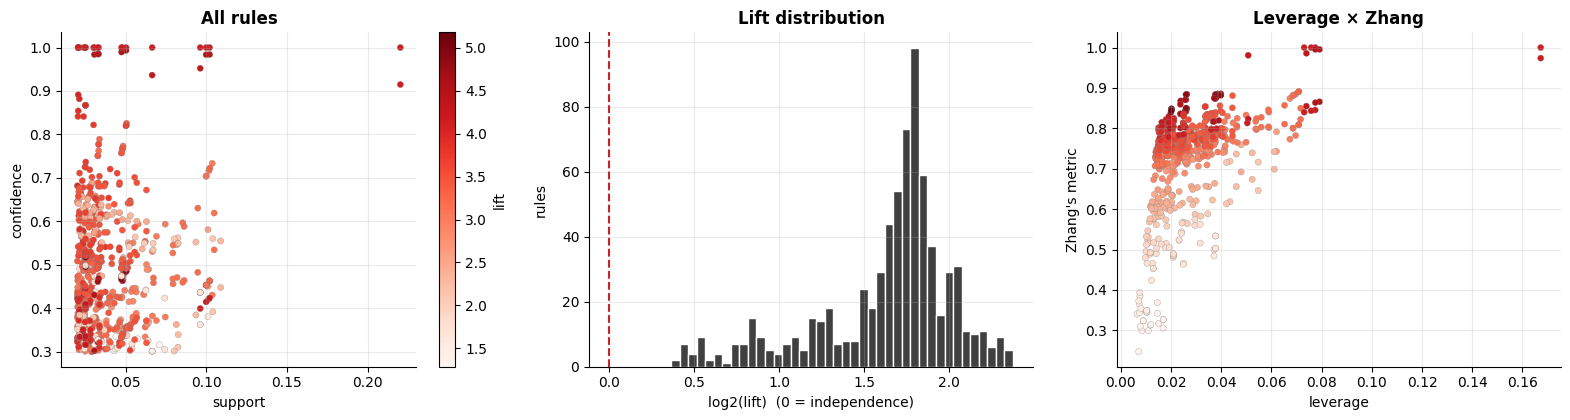

In [13]:
#Visualise the Rules ( Support × Confidence Colored by Lift, and Metric Distributions )
fig, axes = plt.subplots(1, 3, figsize=(16, 4.3))
sc = axes[0].scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="Reds", s=20, edgecolor=GRAY, lw=0.2)
axes[0].set_xlabel("support"); axes[0].set_ylabel("confidence"); axes[0].set_title("All rules"); fig.colorbar(sc, ax=axes[0], label="lift")
axes[1].hist(np.log2(rules["lift"]), bins=40, color=DARK, edgecolor="white"); axes[1].axvline(0, color=RED, ls="--"); axes[1].set_xlabel("log2(lift)  (0 = independence)"); axes[1].set_ylabel("rules"); axes[1].set_title("Lift distribution")
axes[2].scatter(rules["leverage"], rules["zhangs"], c=rules["lift"], cmap="Reds", s=20, edgecolor=GRAY, lw=0.2); axes[2].set_xlabel("leverage"); axes[2].set_ylabel("Zhang's metric"); axes[2].set_title("Leverage × Zhang")
plt.tight_layout(); plt.show()

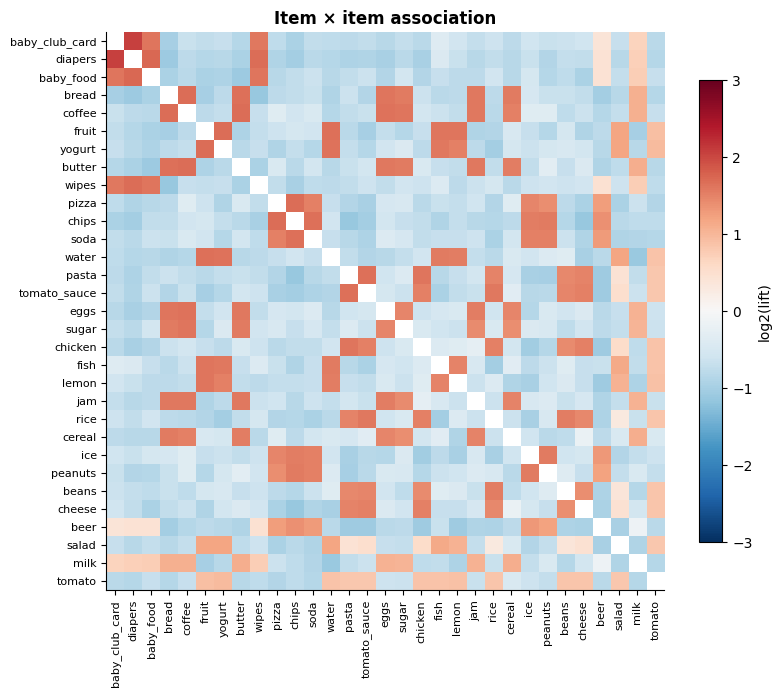

In [14]:
#Lift Between Item Pairs ( log2 scale: red = bought together more than expected, blue = less )
B_mat = np.array([[i in t for i in items] for t in transactions], dtype=float)
co = B_mat.T @ B_mat / N
sup = np.diag(co)
lift_pairs = co / np.outer(sup, sup)
np.fill_diagonal(lift_pairs, np.nan)
order = np.argsort(-np.nan_to_num(lift_pairs, nan=0).max(axis=1))

fig, ax = plt.subplots(figsize=(9, 8))
im = ax.imshow(np.log2(lift_pairs[np.ix_(order, order)]), cmap="RdBu_r", vmin=-3, vmax=3); ax.grid(False)
ax.set_xticks(range(len(items))); ax.set_xticklabels([items[i] for i in order], rotation=90, fontsize=8)
ax.set_yticks(range(len(items))); ax.set_yticklabels([items[i] for i in order], fontsize=8)
fig.colorbar(im, ax=ax, shrink=0.75, label="log2(lift)"); ax.set_title("Item × item association")
plt.show()

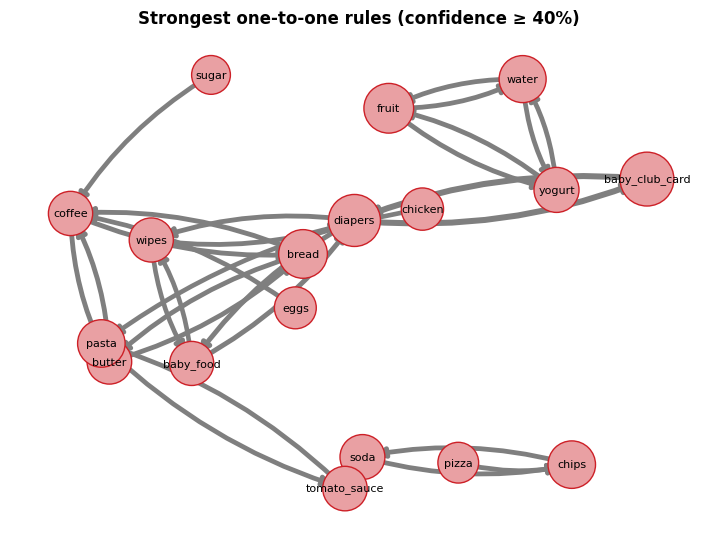

In [15]:
#Network of the Strongest Rules ( Node Size = Support, Edge Width = Lift )
import networkx as nx

single = rules[(rules["antecedent"].map(len) == 1) & (rules["consequent"].map(len) == 1) & (rules["confidence"] >= 0.4)].sort_values("lift", ascending=False).head(28)
G = nx.DiGraph()
for r in single.itertuples():
    G.add_edge(r.antecedent[0], r.consequent[0], lift=r.lift, conf=r.confidence)
pos = nx.spring_layout(G, seed=RANDOM_STATE, k=1.1)
fig, ax = plt.subplots(figsize=(9, 6.5))
nx.draw_networkx_nodes(G, pos, node_size=[300 + 5000 * freq_apriori[frozenset([n])] for n in G.nodes], node_color=SOFT, edgecolors=RED, ax=ax)
nx.draw_networkx_edges(G, pos, width=[0.6 + 0.9 * G[u][v]["lift"] for u, v in G.edges], edge_color=GRAY, arrows=True, arrowsize=14, connectionstyle="arc3,rad=0.12", ax=ax)
nx.draw_networkx_labels(G, pos, font_size=8, ax=ax); ax.axis("off"); ax.set_title("Strongest one-to-one rules (confidence ≥ 40%)")
plt.show()

### **9. Reducing the Output: Closed and Maximal Itemsets, Redundant Rules**

* **Closed:** no superset with the **same support** (loses no information)
* **Maximal:** no **frequent** superset (the borders of the frequent region; loses the supports)
* A rule is **redundant** when a rule with a **simpler antecedent** has the same consequent and confidence ≥

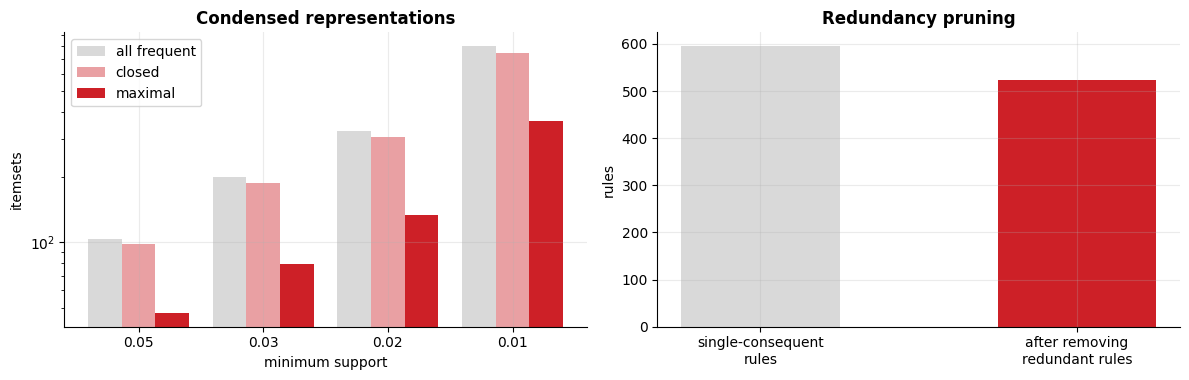

,min_support,all,closed,maximal
0,0.05,104,98,47
1,0.03,199,187,79
2,0.02,326,307,133
3,0.01,806,749,361


redundant rules removed: 71 of 595 (12%)


In [16]:
#Closed and Maximal Itemsets by Minimum Support, and Redundant Rules
def closed_maximal(freq):
    all_items = {i for s in freq for i in s}
    closed = maximal = 0
    for s, sup in freq.items():
        supers = [freq.get(s | {x}) for x in all_items - s]
        closed += all(v is None or abs(v - sup) > 1e-12 for v in supers)
        maximal += all(v is None for v in supers)
    return closed, maximal

rows = []
for ms in [0.05, 0.03, 0.02, 0.01]:
    f, _ = eclat(tid_all, N, ms)
    c_, m_ = closed_maximal(f)
    rows.append({"min_support": ms, "all": len(f), "closed": c_, "maximal": m_})
cm = pd.DataFrame(rows)

def drop_redundant(rules):
    single = rules[rules["consequent"].map(len) == 1]
    conf = {(r.antecedent, r.consequent): r.confidence for r in single.itertuples()}
    keep = []
    for r in single.itertuples():
        red = any(conf.get((sub, r.consequent), -1) >= r.confidence for k in range(1, len(r.antecedent)) for sub in combinations(r.antecedent, k))
        keep.append(not red)
    return single[keep]

non_red = drop_redundant(rules)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
x = np.arange(len(cm))
axes[0].bar(x - 0.27, cm["all"], 0.27, color=LIGHT, label="all frequent"); axes[0].bar(x, cm["closed"], 0.27, color=SOFT, label="closed"); axes[0].bar(x + 0.27, cm["maximal"], 0.27, color=RED, label="maximal")
axes[0].set_xticks(x); axes[0].set_xticklabels(cm["min_support"]); axes[0].set_xlabel("minimum support"); axes[0].set_ylabel("itemsets"); axes[0].set_yscale("log"); axes[0].set_title("Condensed representations"); axes[0].legend()
n_single = int((rules["consequent"].map(len) == 1).sum())
axes[1].bar(["single-consequent\nrules", "after removing\nredundant rules"], [n_single, len(non_red)], color=[LIGHT, RED], width=0.5); axes[1].set_ylabel("rules"); axes[1].set_title("Redundancy pruning")
plt.tight_layout(); plt.show()
display(cm)
print(f"redundant rules removed: {n_single - len(non_red)} of {n_single} ({(n_single - len(non_red)) / n_single:.0%})")

### **10. Evaluating the Rules as a Predictive Model**

Do the rules **predict** purchases on baskets they have never seen?

* **Task A (binary):** hide `beer` in each test basket and predict whether it was there. Score = the highest **confidence** among the rules `A ⇒ beer` that fire (otherwise, the item's base rate)
* **Task B (recommendation):** hide **one random item** and rank all the others; metric = **hit-rate@k**

Rules are mined from the **training baskets (70%)** only.

In [17]:
#Split the Baskets and Mine the Rules on the Training Baskets ( min support 0.5%, min confidence 5% )
perm = np.random.default_rng(RANDOM_STATE).permutation(len(transactions))
train_tx = [transactions[i] for i in perm[:4200]]
test_tx = [transactions[i] for i in perm[4200:]]

tid_tr = build_tidsets(train_tx)
freq_tr, _ = eclat(tid_tr, len(train_tx), min_support=0.005)
rules_tr = generate_rules(freq_tr, min_confidence=0.05)
print("train baskets:", len(train_tx), "| test baskets:", len(test_tx), "| frequent itemsets:", len(freq_tr), "| rules:", len(rules_tr))

train baskets: 4200 | test baskets: 1800 | frequent itemsets: 2158 | rules: 12936


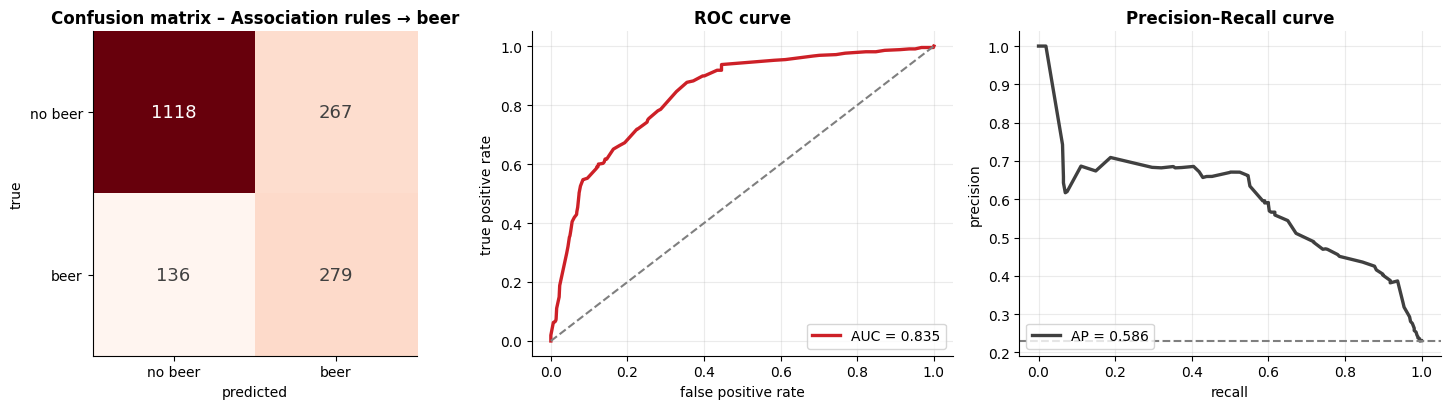

,PR AUC,ROC AUC,accuracy,precision,recall
association rules,0.586,0.835,0.776,0.511,0.672
baseline (constant score),0.231,0.500,NaN,NaN,NaN


In [18]:
#Task A: Predict Whether a Basket Contains "beer" ( Evaluation with the Generic ML Metrics )
TARGET = "beer"
beer_rules = rules_tr[rules_tr["consequent"] == (TARGET,)][["antecedent", "confidence"]].copy()
prior_beer = tid_tr[TARGET].bit_count() / len(train_tx)

def score_beer(basket):
    visible = set(basket) - {TARGET}
    fired = [r.confidence for r in beer_rules.itertuples() if set(r.antecedent) <= visible]
    return max(fired) if fired else prior_beer

y_true = np.array([TARGET in t for t in test_tx]).astype(int)
score_rules = np.array([score_beer(t) for t in test_tx])
base_rate = np.full(len(test_tx), prior_beer)                                                                    # baseline: no information (constant score)
threshold = 0.5
res_a = report_binary(y_true, (score_rules >= threshold).astype(int), score_rules, "Association rules → beer", ["no beer", "beer"])
pd.DataFrame({"association rules": res_a[["accuracy", "recall", "precision", "ROC AUC", "PR AUC"]],
              "baseline (constant score)": pd.Series({"ROC AUC": roc_auc_score(y_true, base_rate), "PR AUC": y_true.mean()})}).T

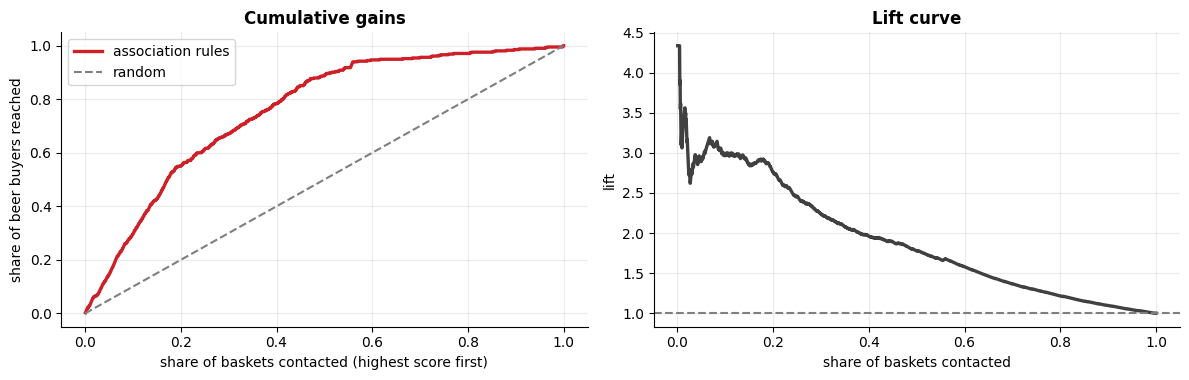

top 10% of the baskets contain 68.3% beer buyers vs 23.1% overall → lift 2.96


In [19]:
#Business View: Cumulative Gains and Lift Curve ( Who Should Receive a Beer Coupon? )
order = np.argsort(-score_rules)
gain = np.cumsum(y_true[order]) / y_true.sum()
frac = np.arange(1, len(order) + 1) / len(order)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.9))
axes[0].plot(frac, gain, color=RED, lw=2.4, label="association rules"); axes[0].plot([0, 1], [0, 1], color=GRAY, ls="--", label="random"); axes[0].set_xlabel("share of baskets contacted (highest score first)")
axes[0].set_ylabel("share of beer buyers reached"); axes[0].set_title("Cumulative gains"); axes[0].legend()
axes[1].plot(frac, gain / frac, color=DARK, lw=2.4); axes[1].axhline(1, color=GRAY, ls="--"); axes[1].set_xlabel("share of baskets contacted"); axes[1].set_ylabel("lift"); axes[1].set_title("Lift curve")
plt.tight_layout(); plt.show()
top_decile = int(len(order) * 0.1)
print(f"top 10% of the baskets contain {y_true[order][:top_decile].mean():.1%} beer buyers vs {y_true.mean():.1%} overall → lift {y_true[order][:top_decile].mean() / y_true.mean():.2f}")

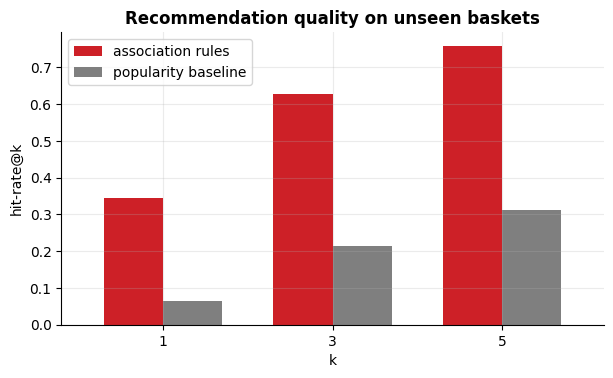

,association rules,popularity baseline
k,,
1,0.344,0.064
3,0.628,0.215
5,0.758,0.312


In [20]:
#Task B: Recommendation ( Hide One Item and Rank the Others ) – Hit-Rate@k vs a Popularity Baseline
item_idx = {i: k for k, i in enumerate(items)}
single_rules = rules_tr[rules_tr["consequent"].map(len) == 1]
ante_mask = np.array([sum(1 << item_idx[i] for i in a) for a in single_rules["antecedent"]], dtype=np.int64)
cons_idx = np.array([item_idx[c[0]] for c in single_rules["consequent"]])
conf_arr = single_rules["confidence"].to_numpy()
popularity = np.array([tid_tr.get(i, 0).bit_count() / len(train_tx) for i in items])

rng_b = np.random.default_rng(RANDOM_STATE)
hits_rules, hits_pop, n_eval = {1: 0, 3: 0, 5: 0}, {1: 0, 3: 0, 5: 0}, 0
for t in test_tx:
    if len(t) < 2:
        continue
    hidden = list(t)[rng_b.integers(len(t))]
    visible = np.int64(sum(1 << item_idx[i] for i in t if i != hidden))
    fires = (ante_mask & visible) == ante_mask
    score = np.zeros(len(items)); np.add.at(score, cons_idx[fires], conf_arr[fires])
    score += 1e-6 * popularity                                                       # popularity breaks ties
    for i in t:
        if i != hidden:
            score[item_idx[i]] = -1; 
    pop = popularity.copy()
    for i in t:
        if i != hidden:
            pop[item_idx[i]] = -1
    for k in hits_rules:
        hits_rules[k] += hidden in {items[j] for j in np.argsort(-score)[:k]}
        hits_pop[k] += hidden in {items[j] for j in np.argsort(-pop)[:k]}
    n_eval += 1

hit = pd.DataFrame({"association rules": {k: v / n_eval for k, v in hits_rules.items()}, "popularity baseline": {k: v / n_eval for k, v in hits_pop.items()}})
hit.index.name = "k"
hit.plot.bar(color=[RED, GRAY], width=0.7, rot=0, figsize=(7, 3.8)); plt.ylabel("hit-rate@k"); plt.title("Recommendation quality on unseen baskets")
plt.show()
hit.round(3)

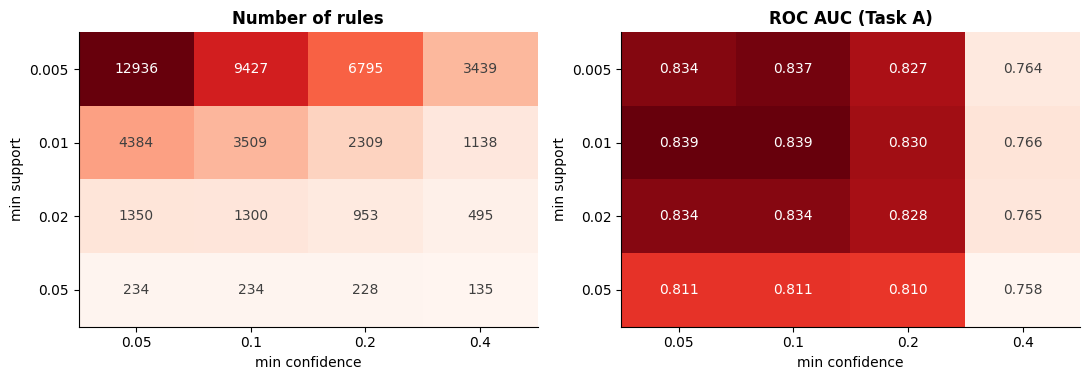

In [21]:
#Sensitivity: How Thresholds Change the Number of Rules and the Quality of Task A
sup_grid, conf_grid = [0.005, 0.01, 0.02, 0.05], [0.05, 0.1, 0.2, 0.4]
n_r, auc_r = np.zeros((4, 4)), np.zeros((4, 4))
for i, s in enumerate(sup_grid):
    for j, c in enumerate(conf_grid):
        r = rules_tr[(rules_tr["support"] >= s) & (rules_tr["confidence"] >= c)]
        n_r[i, j] = len(r)
        br = r[r["consequent"] == (TARGET,)]
        sc_ = np.array([max([x.confidence for x in br.itertuples() if set(x.antecedent) <= (set(t) - {TARGET})], default=prior_beer) for t in test_tx])
        auc_r[i, j] = roc_auc_score(y_true, sc_ + np.random.default_rng(1).normal(0, 1e-9, len(sc_)))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.9))
for ax, mat, title, fmt_ in [(axes[0], n_r, "Number of rules", "{:.0f}"), (axes[1], auc_r, "ROC AUC (Task A)", "{:.3f}")]:
    ax.imshow(mat, cmap="Reds", aspect="auto"); ax.grid(False); ax.set_xticks(range(4)); ax.set_xticklabels(conf_grid); ax.set_yticks(range(4)); ax.set_yticklabels(sup_grid)
    ax.set_xlabel("min confidence"); ax.set_ylabel("min support"); ax.set_title(title); annotate_heatmap(ax, mat, fmt_)
plt.tight_layout(); plt.show()

### **11. Summary**

| | **Apriori** | **FP-Growth** | **Eclat** |
|---|---|---|---|
| Strategy | breadth-first, candidates | FP-tree, no candidates | depth-first, tid-list intersections |
| Memory | candidates per level | the FP-tree | tid-lists |
| Specific metrics | candidates, pruning, passes | tree nodes, compression | intersections |
| In practice | `mlxtend.frequent_patterns.apriori` | `mlxtend.frequent_patterns.fpgrowth` | – |

* **Rules are descriptive:** high lift does not mean **causality** (diapers do not *cause* beer purchases)
* Choose *min_support* by the **search space** (section 7) and rank rules by **lift / leverage**, not by confidence alone
* Evaluate rules on **unseen baskets** (section 10) before using them for recommendation or campaigns